In [1]:
from utils.config import GOALS
from utils.simulations import generate_cases

cases_df = generate_cases(GOALS, num_samples_per_goal=5)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df

,goal,tp,wd,ds,zs
0,1,2.366899,97.523185,34.931395,-3.428109
1,1,8.526872,331.166322,37.716217,2.927121
2,1,13.461138,1.377956,11.969085,-0.053401
3,1,5.676751,299.421435,7.131886,1.465103
4,1,11.824683,120.155649,25.609594,-1.067239
...,...,...,...,...,...
65,14,2.366899,261.473649,34.931395,-3.428109
66,14,8.526872,132.589649,37.716217,2.927121
67,14,13.461138,163.405515,11.969085,-0.053401
68,14,5.676751,100.209864,7.131886,1.465103


<Axes: xlabel='tp', ylabel='wd'>

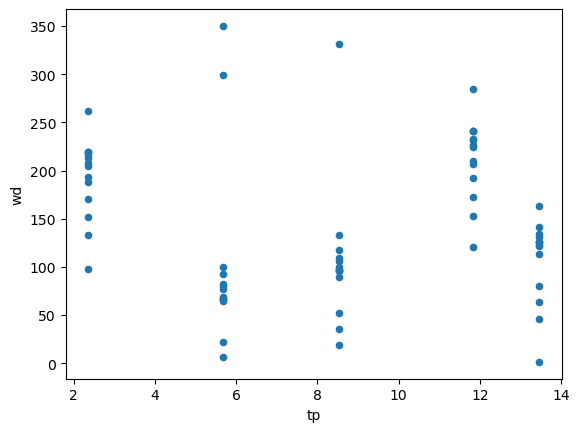

In [2]:
cases_df.plot.scatter(x="tp", y="wd")

In [3]:
from utils.snapwave_wrapper import SnapWaveMetaModelWrapper

# Auto-loads the `output_sites` config: `build_case` drops `output_sites.txt`
# into each case dir, and `postprocess_case` relabels SnapWave stations as
# `10m_0`, `20m_65`, `buoy_41013`, ... using the in-memory `output_sites_df`.
snapwave_wrapper = SnapWaveMetaModelWrapper(
    templates_dir="templates-metamodel",
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={},
    output_dir="SnapWave_CASES_METAMODEL",
    aoi_file="inputs/AoI_Polygons/AoI_NorthCarolina.shp",
    goals_config=GOALS,
)
snapwave_wrapper

2026-06-16 13:51:42,309 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-06-16 13:51:42,309 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-06-16 13:51:42,309 - SnapWaveMetaModelWrapper - WARNING - Parameter wd is not in the default_parameters
2026-06-16 13:51:42,309 - SnapWaveMetaModelWrapper - WARNING - Parameter ds is not in the default_parameters
2026-06-16 13:51:42,310 - SnapWaveMetaModelWrapper - WARNING - Parameter zs is not in the default_parameters


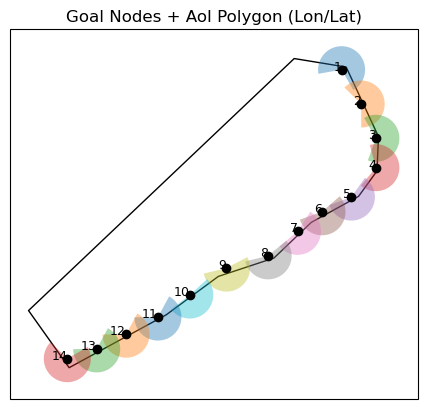

In [4]:
snapwave_wrapper.plot_configuration()

In [5]:
snapwave_wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [6]:
snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [10]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    70
Name: count, dtype: int64

In [11]:
msg = snapwave_wrapper.postprocess_cases()
msg

'Olrait!'

In [17]:
import xarray as xr

xr.open_dataset("SnapWave_CASES_METAMODEL/output_sites_11.nc").sel(case_num=52).isel(
    stations=-20
).load()

<xarray.Dataset> Size: 208B
Dimensions:         ()
Coordinates: (12/13)
    case_num        int64 8B 52
    station_name    <U12 48B 'buoy_OCPN7'
    station_x       float32 4B -78.15
    station_y       float32 4B 33.91
    point_zb        float32 4B nan
    goal            float64 8B 11.0
    ...              ...
    station_label   <U10 40B 'waves'
    station_depth   float64 8B 7.0
    tp              float64 8B 13.46
    wd              float64 8B 126.1
    ds              float64 8B 11.97
    zs              float64 8B -0.0534
Data variables:
    point_zs        float32 4B -0.04862
    point_hm0       float32 4B 0.6881
    point_tp        float32 4B 13.46
    point_wavdir    float32 4B 134.4
    point_dw        float32 4B 28.32
    point_df        float32 4B 1.834
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output